In [100]:
from pathlib import Path

import cmocean as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as signal

import pinner2026_jpo_code
import pinner2026_jpo_code.spectra

RAW_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "raw"
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"

In [61]:
u = pd.read_csv(RAW_DATA_DIR / "moored_ADCP" / "AWI207_bottom_v.csv", skiprows=11, delimiter="\t")
u = u.drop(labels=["Unnamed: 5"], axis="columns")
v = pd.read_csv(RAW_DATA_DIR / "moored_ADCP" / "AWI207_bottom_u.csv", skiprows=11, delimiter="\t")
v = v.drop(labels=["Unnamed: 5"], axis="columns")

In [62]:
assert np.all(u.columns == v.columns)
assert u.shape == v.shape
assert u[["Ens", "HH", "MM", "SS"]].equals(v[["Ens", "HH", "MM", "SS"]])

In [63]:
v.info()

<class 'pandas.DataFrame'>
RangeIndex: 14761 entries, 0 to 14760
Data columns (total 45 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Ens     14761 non-null  int64  
 1   HH      14761 non-null  int64  
 2   MM      14761 non-null  int64  
 3   SS      14761 non-null  int64  
 4   HH.1    14761 non-null  int64  
 5   1       14760 non-null  float64
 6   2       14731 non-null  float64
 7   3       14731 non-null  float64
 8   4       14731 non-null  float64
 9   5       14731 non-null  float64
 10  6       14731 non-null  float64
 11  7       14731 non-null  float64
 12  8       14731 non-null  float64
 13  9       14731 non-null  float64
 14  10      14731 non-null  float64
 15  11      14731 non-null  float64
 16  12      14731 non-null  float64
 17  13      14731 non-null  float64
 18  14      14731 non-null  float64
 19  15      14730 non-null  float64
 20  16      14716 non-null  float64
 21  17      14690 non-null  float64
 22  18      1

- File Size 14.082.048 bytes
- BB/WH Ensemble Length 954 bytes
- System Frequency: 153.6 kHz
- 1st Bin 12,23 m, Bin Size 8,00 m
- No. Bins 40, Pings/Ens 42, Time/Ping 01:25.71
- First Ensemble 00000001 22/04/20 15:09:47.16
- Last  Ensemble 00014761 23/12/26 15:09:47.16 Extra Data in File
- Average Ensemble Interval 00:10:20,69
- distance from ground: 10 m

In [64]:
DISTANCE_FROM_GROUND_METERS = 10.0
DISTANCE_FROM_ADCP = 12.23
VERTICAL_BIN_SIZE = 8.0
FIRST_DAY = pd.to_datetime("22/04/20", yearfirst=True)
FIRST_ENSEMBLE = pd.to_datetime("22/04/20 15:09:47.16", yearfirst=True)
LAST_ENSEMBLE = pd.to_datetime("23/12/26 15:09:47.16", yearfirst=True)
ENSEMBLE_COUNT = u.shape[0]
print(FIRST_ENSEMBLE)
print(LAST_ENSEMBLE)

2022-04-20 15:09:47.160000
2023-12-26 15:09:47.160000


In [65]:
# Get the start time from the first row
start_time = pd.Timedelta(hours=u["HH"].iloc[0], minutes=u["MM"].iloc[0], seconds=u["SS"].iloc[0])

# Compute each row's timedelta from midnight of the start date
row_times = (
    pd.to_timedelta(u["HH"], unit="h")
    + pd.to_timedelta(u["MM"], unit="m")
    + pd.to_timedelta(u["SS"], unit="s")
)

# Find where the time rolls over (i.e. row time < previous row time)
# and compute a day offset that increments at each rollover
day_offsets = (row_times < row_times.shift(1, fill_value=row_times.iloc[0])).cumsum()

# Combine: start_date + day_offset + row_time
timestamps = FIRST_DAY + pd.to_timedelta(day_offsets, unit="D") + row_times
assert LAST_ENSEMBLE - timestamps.iloc[-1] < pd.to_timedelta(1, unit="s")

u.index = timestamps
v.index = timestamps
u = u.drop(labels=["Ens", "HH", "MM", "SS", "HH.1"], axis="columns")
v = v.drop(labels=["Ens", "HH", "MM", "SS", "HH.1"], axis="columns")

In [66]:
u.columns = (
    DISTANCE_FROM_GROUND_METERS + DISTANCE_FROM_ADCP + u.columns.astype(int) * VERTICAL_BIN_SIZE
).round(2)
v.columns = (
    DISTANCE_FROM_GROUND_METERS + DISTANCE_FROM_ADCP + v.columns.astype(int) * VERTICAL_BIN_SIZE
).round(2)

In [67]:
# conversion from mm/s to m/s
u = u / 100
v = v / 100

Text(0.5, 0, 'v / (m/s)')

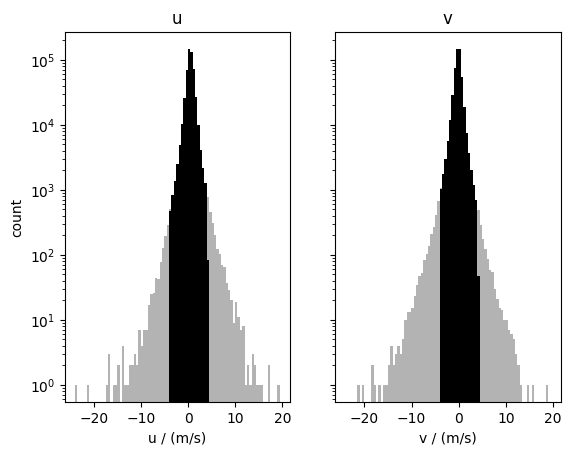

In [68]:
fig, ax = plt.subplots(ncols=2, sharex=True, sharey=True)
binwidth = 0.5
ubins = np.arange(u.min(axis=None), u.max(axis=None) + binwidth, binwidth)
vbins = np.arange(u.min(axis=None), u.max(axis=None) + binwidth, binwidth)
ax[0].hist(u.to_numpy().flatten(), bins=ubins, log=True, color="0.7")
ax[1].hist(v.to_numpy().flatten(), bins=vbins, log=True, color="0.7")

ut = u.copy()
vt = v.copy()

MAX_REASONABLE_VELOCITY = 4  # m/s
# remove everything faster than MAX_REASONABLE_VELOCITY
ut[u.abs() > MAX_REASONABLE_VELOCITY] = np.nan
vt[v.abs() > MAX_REASONABLE_VELOCITY] = np.nan

ax[0].hist(ut.to_numpy().flatten(), bins=ubins, log=True, color="k")
ax[1].hist(vt.to_numpy().flatten(), bins=vbins, log=True, color="k")

ax[0].set_title("u")
ax[1].set_title("v")

ax[0].set_ylabel("count")

ax[0].set_xlabel("u / (m/s)")
ax[1].set_xlabel("v / (m/s)")

# for axis in ax:
#     axis.axvline(MAX_REASONABLE_VELOCITY, color="tab:red", ls = "--")
#     axis.axvline(-MAX_REASONABLE_VELOCITY, color="tab:red", ls = "--")

In [69]:
ut.to_csv(INTERIM_DATA_DIR / "AWI207_bottom_u.csv")
vt.to_csv(INTERIM_DATA_DIR / "AWI207_bottom_v.csv")

In [70]:
uclean = pd.read_csv(INTERIM_DATA_DIR / "AWI207_bottom_u.csv", parse_dates=True, index_col=0)
uclean.columns = uclean.columns.astype(float)
vclean = pd.read_csv(INTERIM_DATA_DIR / "AWI207_bottom_v.csv", parse_dates=True, index_col=0)
vclean.columns = vclean.columns.astype(float)

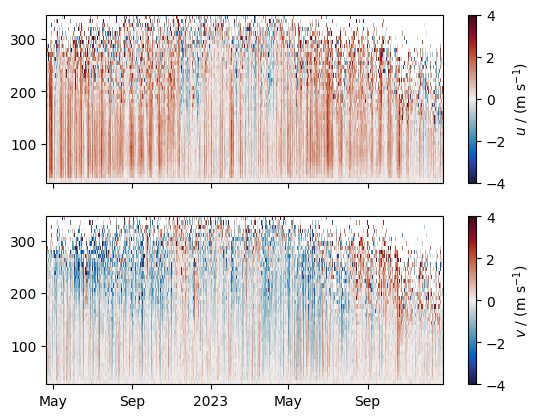

In [134]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True)

max_plot_velocity = MAX_REASONABLE_VELOCITY
# max_plot_velocity= 2

im0 = ax[0].pcolormesh(
    uclean.index,
    uclean.columns,
    uclean.to_numpy().T,
    norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-max_plot_velocity, vmax=max_plot_velocity),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    vclean.index,
    vclean.columns,
    vclean.to_numpy().T,
    norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-max_plot_velocity, vmax=max_plot_velocity),
    cmap=cm.cm.balance,
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

for axis in ax:
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

In [72]:
# u.describe()

In [73]:
u_shear = pd.DataFrame(
    np.gradient(uclean.values, uclean.columns, axis=1), index=uclean.index, columns=uclean.columns
)

v_shear = pd.DataFrame(
    np.gradient(vclean.values, vclean.columns, axis=1), index=vclean.index, columns=vclean.columns
)

Su = u_shear**2
Sv = v_shear**2

u_shear_control = uclean.diff(axis=1) / VERTICAL_BIN_SIZE
v_shear_control = vclean.diff(axis=1) / VERTICAL_BIN_SIZE
Su_control = u_shear_control**2
Sv_control = v_shear_control**2

In [74]:
# plt.hist((Sv- Sv_control).to_numpy().flatten(), log=True, bins=20)

Text(0.5, 0, '$S_v^2$ / (s$^{-2}$)')

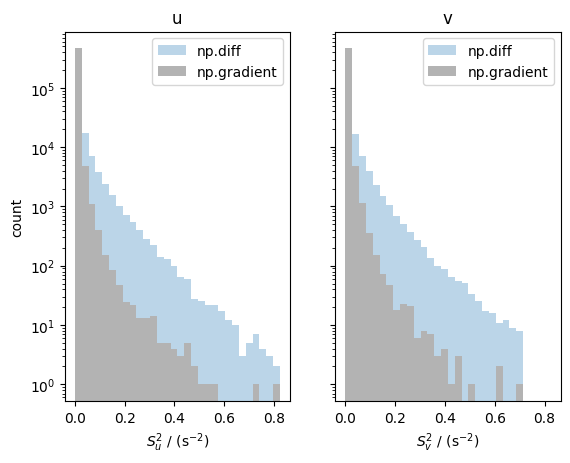

In [75]:
fig, ax = plt.subplots(ncols=2, sharex=True, sharey=True)
binwidth = (Su.max(axis=None) - Su.min(axis=None)) / 30
ubins = np.arange(Su.min(axis=None), Su.max(axis=None) + binwidth, binwidth)
vbins = np.arange(Sv.min(axis=None), Sv.max(axis=None) + binwidth, binwidth)

ax[0].hist(
    Su_control.to_numpy().flatten(),
    bins=ubins,
    log=True,
    color="tab:blue",
    alpha=0.3,
    label="np.diff",
)
ax[1].hist(
    Sv_control.to_numpy().flatten(),
    bins=vbins,
    log=True,
    color="tab:blue",
    alpha=0.3,
    label="np.diff",
)

ax[0].hist(Su.to_numpy().flatten(), bins=ubins, log=True, color="0.7", label="np.gradient")
ax[1].hist(Sv.to_numpy().flatten(), bins=vbins, log=True, color="0.7", label="np.gradient")

ax[0].set_title("u")
ax[1].set_title("v")
ax[0].legend()
ax[1].legend()
ax[0].set_ylabel("count")

ax[0].set_xlabel("$S_u^2$ / (s$^{-2}$)")
ax[1].set_xlabel("$S_v^2$ / (s$^{-2}$)")

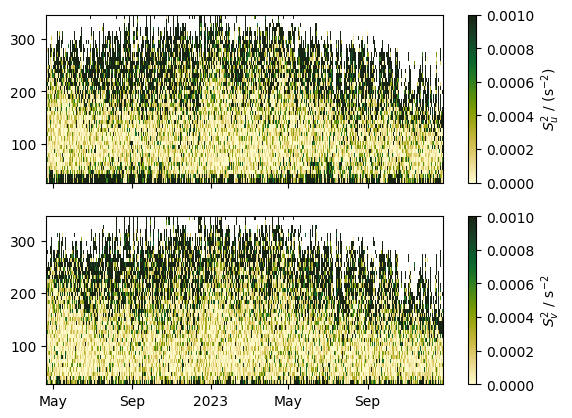

In [76]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True)

# max_plot_shear =  2* MAX_REASONABLE_VELOCITY / VERTICAL_BIN_SIZE
max_plot_shear_squared = 1 * 1e-3

norm = mcolors.LogNorm(vmin=1e-6, vmax=1e-2)
norm = mcolors.PowerNorm(gamma=1, vmin=0, vmax=1e-3)

im0 = ax[0].pcolormesh(Su.index, Su.columns, Su.to_numpy().T, norm=norm, cmap=cm.cm.speed)


im1 = ax[1].pcolormesh(Sv.index, Sv.columns, Sv.to_numpy().T, norm=norm, cmap=cm.cm.speed)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$S_u^2$ / (s$^{-2}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$S_v^2$ / s$^{-2}$")

for axis in ax:
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

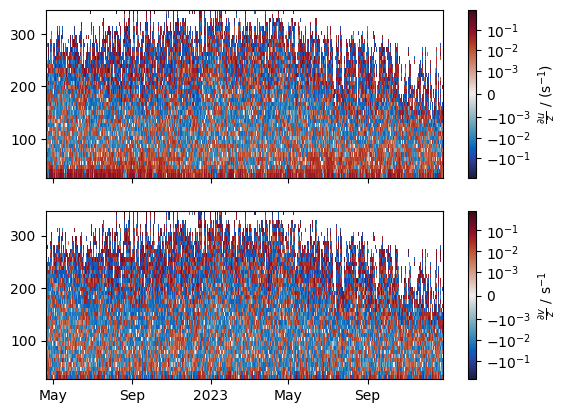

In [135]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True)

linthresh = 1e-3

im0 = ax[0].pcolormesh(
    u_shear.index,
    u_shear.columns,
    u_shear.to_numpy().T,
    norm=mcolors.SymLogNorm(linthresh),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_shear.index,
    v_shear.columns,
    v_shear.to_numpy().T,
    norm=mcolors.SymLogNorm(linthresh),
    cmap=cm.cm.balance,
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$\\frac{\\partial u}{z}$ / (s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$\\frac{\\partial v}{z}$ / s$^{-1}$")

for axis in ax:
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

NameError: name 'max_plot_shear' is not defined

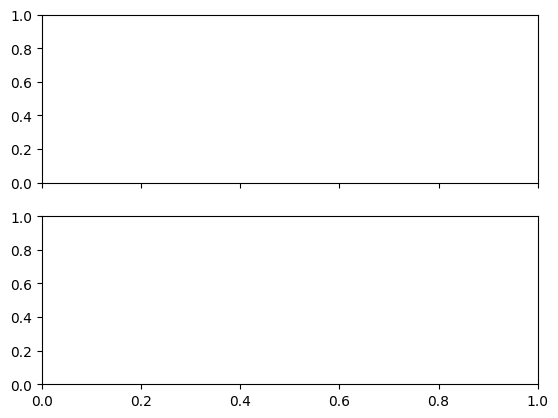

In [78]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True)

# max_plot_shear = 2 * MAX_REASONABLE_VELOCITY / VERTICAL_BIN_SIZE
# max_plot_shear = max_plot_shear * 1e-3
# #max_plot_shear= 2

im0 = ax[0].pcolormesh(
    u_shear.index,
    u_shear.columns,
    u_shear.to_numpy().T,
    norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-max_plot_shear, vmax=max_plot_shear),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_shear.index,
    v_shear.columns,
    v_shear.to_numpy().T,
    norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-max_plot_shear, vmax=max_plot_shear),
    cmap=cm.cm.balance,
)

fig.colorbar(im0, ax=ax[0])
fig.colorbar(im1, ax=ax[1])

for axis in ax:
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

# Test

In [79]:
# uclean.isna().sum()

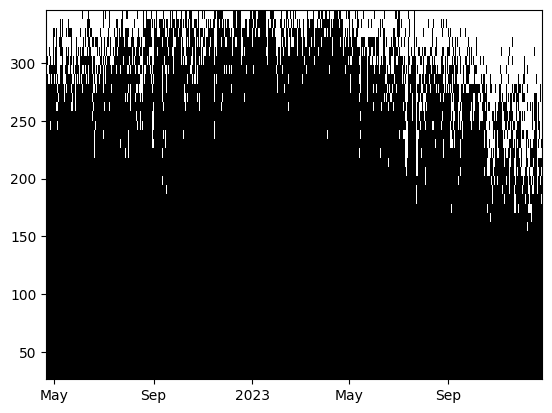

In [80]:
fig, ax = plt.subplots(1)

im0 = ax.pcolormesh(uclean.index, uclean.columns, ~uclean.isna().T.to_numpy(), cmap="Greys")

locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

In [81]:
u_series = uclean[102.23][30:]
v_series = uclean[102.23][30:]
# time_series[102.23]
assert not np.any(time_series.isna())

In [122]:
fs = 1 / (1 * 60 * 60)  # sampling period of 1 hour
cut = 1 / (13.3 * 60 * 60)  # Coriolis period of 1.8cpd
order = 40

sos = signal.butter(N=order, Wn=cut, btype="highpass", fs=fs, output="sos")
# use filtfilt with 2 filtering passes to prevent an artificial phase shift
superinertial_u = pd.Series(index=u_series.index, data=signal.sosfiltfilt(sos, u_series.values))
superinertial_v = pd.Series(index=v_series.index, data=signal.sosfiltfilt(sos, v_series.values))

(0.0008, 3)

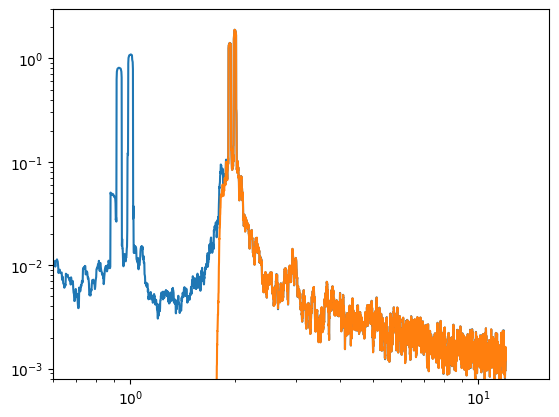

In [126]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 10
freq, velocity_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    u_series.values, dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
plt.loglog(freq, velocity_spectrum)
freq, velocity_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    superinertial_u.values, dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
plt.loglog(freq, velocity_spectrum)
plt.gca().set_xlim(0.6, 16)
plt.gca().set_ylim(8e-4, 3)

<Axes: >

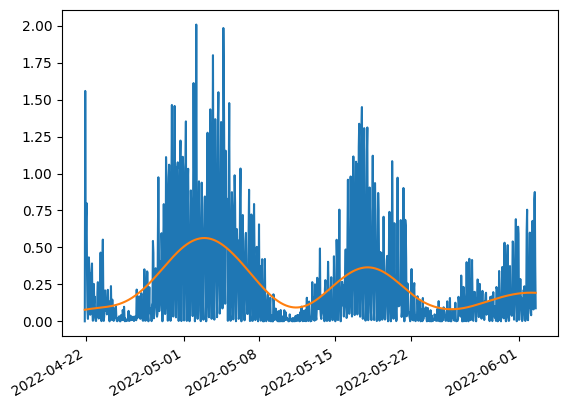

In [179]:
hke = 1 / 2 * (superinertial_u + 1j * superinertial_v).abs() ** 2
hke[:1000].plot()


def smooth(array, length):
    window = signal.windows.hann(length)  # construct Hanning window
    # smooth by convolving speed with window
    smoothed = signal.convolve(array, window, mode="same") / np.sum(window)
    return smoothed


smooth_hke = pd.Series(index=hke.index, data=smooth(hke.to_numpy(), 300))
smooth_hke[:1000].plot()

In [159]:
inertial_wind = pd.read_csv(INTERIM_DATA_DIR / "inertial_wind_2022_2023.csv")
inertial_wind = inertial_wind.set_index(pd.to_datetime(inertial_wind["Unnamed: 0"]))
inertial_wind = inertial_wind.drop("Unnamed: 0", axis="columns")
for _i, col in enumerate(inertial_wind.columns):
    inertial_wind[col] = inertial_wind[col].str.replace("i", "j").apply(lambda x: complex(x))
inertial_wind_at_C = inertial_wind["C"]
inertial_wind_at_C = inertial_wind_at_C.loc[: hke.index[-1]]

In [177]:
smooth_wind = pd.Series(
    index=inertial_wind_at_C.index, data=smooth(inertial_wind_at_C.abs().to_numpy(), 300)
)

Text(0, 0.5, 'inertial wind / (m/s)$')

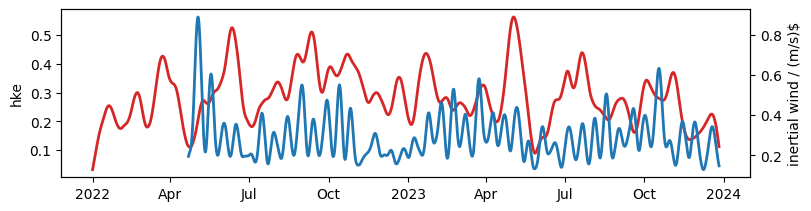

In [180]:
fig, ax = plt.subplots(1, figsize=(8, 2), layout="constrained")

ax.set_ylabel("hke")  # \n$\\varepsilon_{\\mathrm{IGW}}\\,$(W$\\,$kg$^{-1}$)")

locator = mdates.AutoDateLocator(minticks=8, maxticks=12)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

(l_eps,) = ax.plot(
    smooth_hke.index,
    smooth_hke.to_numpy(),
    label="hke",  # $\\varepsilon_\\text{IGW}(t)$",
    lw=2,
)

ax2 = ax.twinx()
ax2.set_zorder(-1)
ax.set_facecolor("None")
(l_tau,) = ax2.plot(
    smooth_wind.index,
    smooth_wind.values,
    color="tab:red",
    label="$\\tau(t)$",
    lw=2,
)

ax2.set_ylabel("inertial wind / (m/s)$")

In [158]:
smooth_wind.abs()

Unnamed: 0
2022-01-01 00:00:00    0.034480
2022-01-01 02:00:00    0.033736
2022-01-01 04:00:00    0.032938
2022-01-01 06:00:00    0.031187
2022-01-01 08:00:00    0.027079
                         ...   
2023-12-26 06:00:00    0.053016
2023-12-26 08:00:00    0.068520
2023-12-26 10:00:00    0.076657
2023-12-26 12:00:00    0.079508
2023-12-26 14:00:00    0.081158
Length: 8696, dtype: float64